In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tips = sns.load_dataset("tips")

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
# Suppose we have to make day wise sale
day_sales = (
    tips.groupby("day", as_index=False)["total_bill"].sum())

day_sales

,day,total_bill
0,Thur,1096.33
1,Fri,325.88
2,Sat,1778.40
3,Sun,1627.16


In [5]:
# Now we will do Visualization of day sales

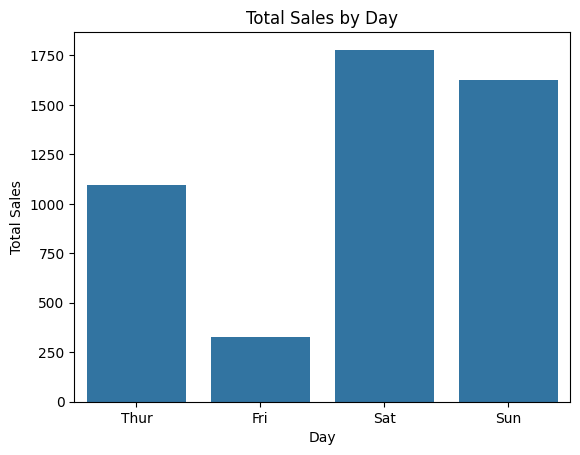

In [6]:
sns.barplot(
    data=day_sales,
    x="day",
    y="total_bill")

plt.title("Total Sales by Day")
plt.xlabel("Day")
plt.ylabel("Total Sales")

plt.show()

In [ ]:
# Bar Chart कब use करें?

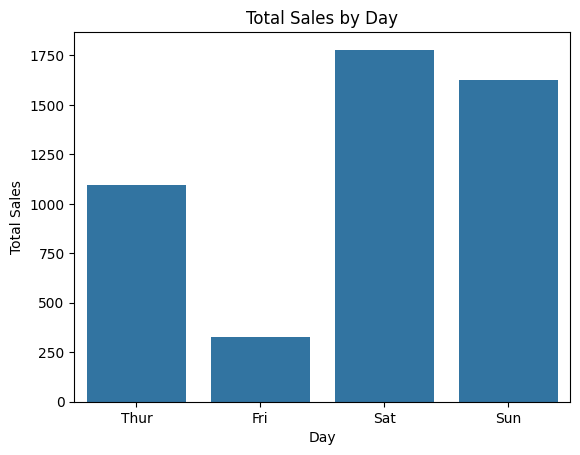

In [7]:
# Bar Chart में Sorting
day_sales = (
    tips.groupby("day", as_index=False)["total_bill"]
        .sum()
        .sort_values("total_bill", ascending=False))

sns.barplot(
    data=day_sales,
    x="day",
    y="total_bill")

plt.title("Total Sales by Day")
plt.xlabel("Day")
plt.ylabel("Total Sales")

plt.show()

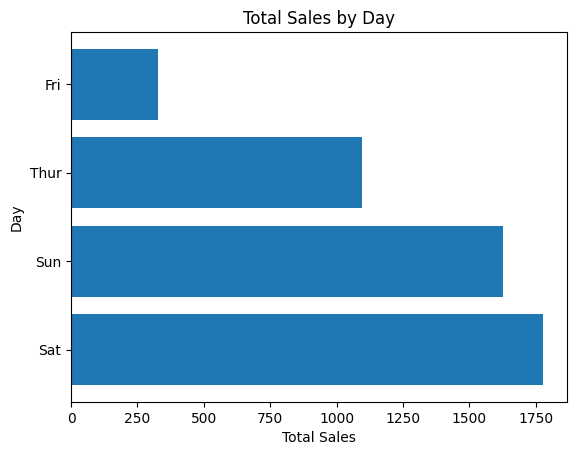

In [8]:
# Horizontal Bar Chart
# अगर category names लंबे हों तो horizontal bar chart ज्यादा readable होता है।
plt.barh(
    day_sales["day"],
    day_sales["total_bill"])

plt.xlabel("Total Sales")
plt.ylabel("Day")
plt.title("Total Sales by Day")

plt.show()

In [ ]:
# Bar Chart vs Histogram

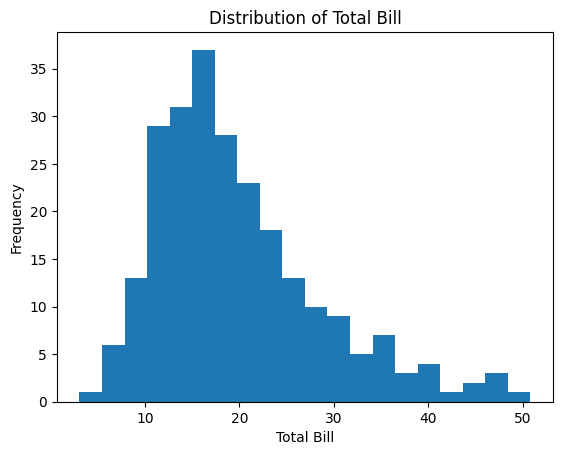

In [9]:
# Histogram
# Restaurant में bill amounts का distribution कैसा है?
plt.hist(tips["total_bill"],bins=20)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.show()

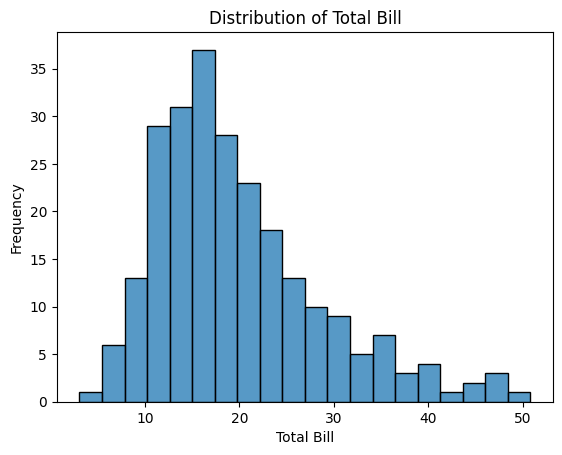

In [11]:
# Seaborn Histogram

sns.histplot(data=tips,x="total_bill",bins=20)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")

plt.show()

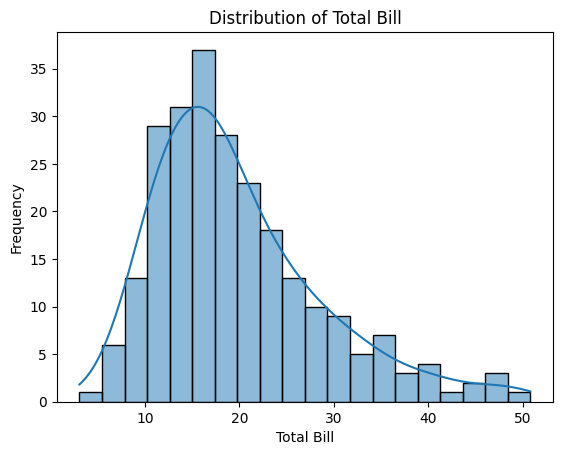

In [12]:
# Seaborn Histogram + KDE हमें distribution curve भी दे सकता है
sns.histplot(data=tips,x="total_bill",bins=20,kde=True)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")

plt.show()

Text(0.5, 1.0, 'Distribution of Total Bill')

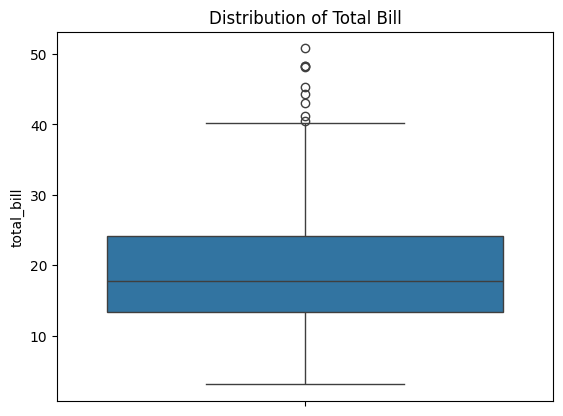

In [13]:
# Box Plot
sns.boxplot(data=tips,
    y="total_bill")

plt.title("Distribution of Total Bill")

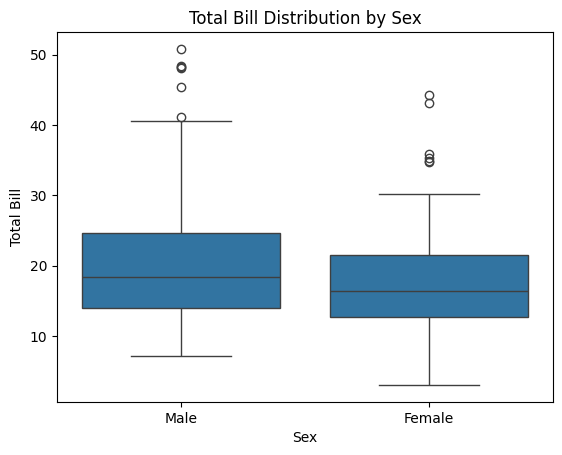

In [14]:
# Box Plot by Category
# Male और Female customers के bill distributions compare करें।

sns.boxplot(
    data=tips,
    x="sex",
    y="total_bill")

plt.title("Total Bill Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Total Bill")

plt.show()

Text(0, 0.5, 'Total Bill')

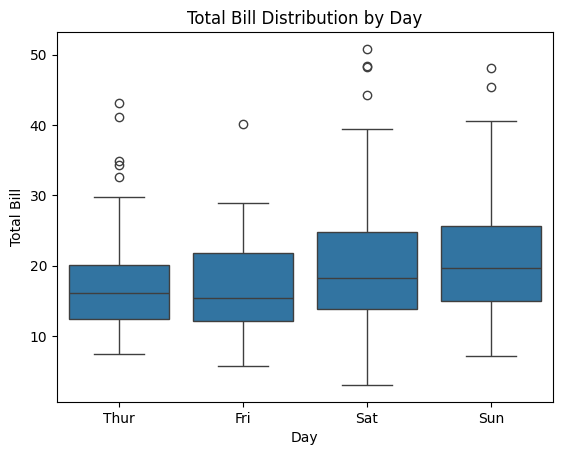

In [15]:
# Box Plot by Day
# इससे हम देख सकते हैं कि अलग-अलग days में bill distribution कैसी है।

sns.boxplot(
    data=tips,
    x="day",
    y="total_bill")

plt.title("Total Bill Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Total Bill")

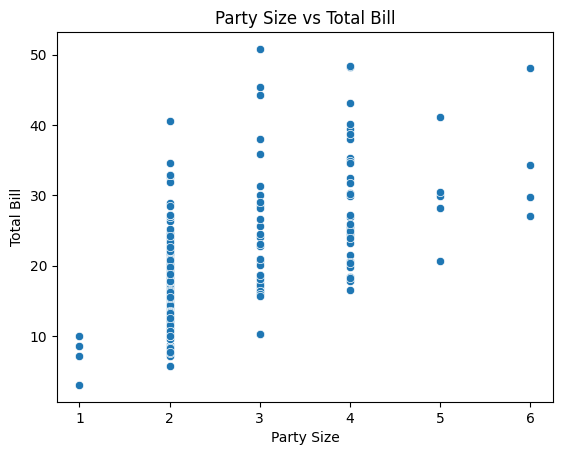

In [16]:
# Scatter Plot: अब relationship analysis
# क्या larger parties ज्यादा total bill generate करती हैं?

sns.scatterplot(
    data=tips,
    x="size",
    y="total_bill")

plt.title("Party Size vs Total Bill")
plt.xlabel("Party Size")
plt.ylabel("Total Bill")

plt.show()

Scatter Plot कब use करें?

जब question हो:
>क्या दो numerical variables के बीच relationship है?

Examples:
>Experience vs Salary
>Temperature vs Sales
>Advertising Spend vs Revenue

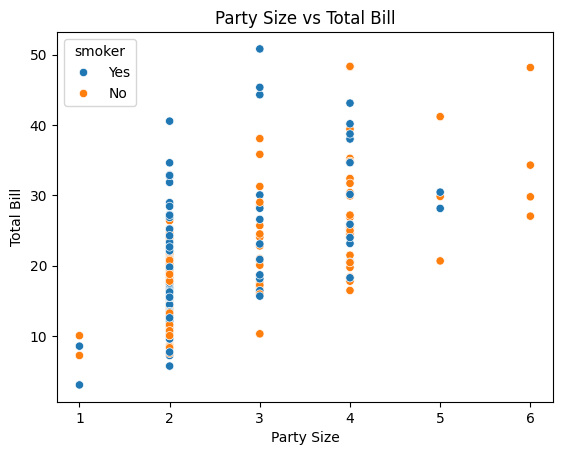

In [17]:
# Scatter Plot में Hue
sns.scatterplot(
    data=tips,
    x="size",
    y="total_bill",
    hue="smoker")

plt.title("Party Size vs Total Bill")
plt.xlabel("Party Size")
plt.ylabel("Total Bill")

plt.show()

In [ ]:
# Hue का Concept
# hue categorical variable के आधार पर points को अलग groups में distinguish करता है।

In [ ]:
# Line Chart

>Line chart primarily trend over an ordered sequence/time के लिए useful होता है।

In [18]:
sales = pd.DataFrame({
    "day": [1, 2, 3, 4, 5, 6, 7],
    "sales": [100, 120, 115, 140, 160, 155, 180]})

sales

,day,sales
0,1,100
1,2,120
2,3,115
3,4,140
4,5,160
5,6,155
6,7,180


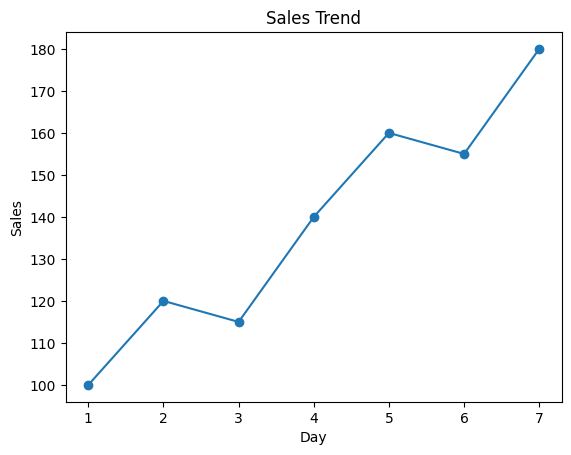

In [19]:
plt.plot(
    sales["day"],
    sales["sales"],
    marker="o")

plt.title("Sales Trend")
plt.xlabel("Day")
plt.ylabel("Sales")

plt.show()

In [20]:
# Line Chart कब use करें?

जब data में order/time हो:
- Date
- Month
- Year
- hour
- Production sequence
- Daily sales
- Monthly revenue

Examples:
- Monthly revenue trend
- Daily production
- Weekly defects

In [21]:
# Count Plot

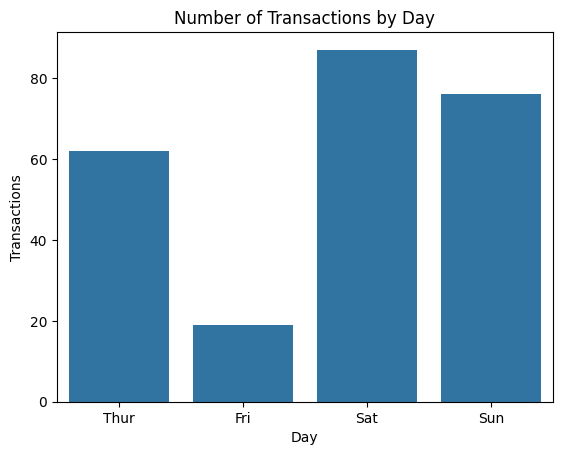

In [22]:
sns.countplot(
    data=tips,
    x="day")

plt.title("Number of Transactions by Day")
plt.xlabel("Day")
plt.ylabel("Transactions")

plt.show()

In [24]:
# Count Plot with Hue
# प्रत्येक day में smoker/non-smoker transactions कितनी हैं?

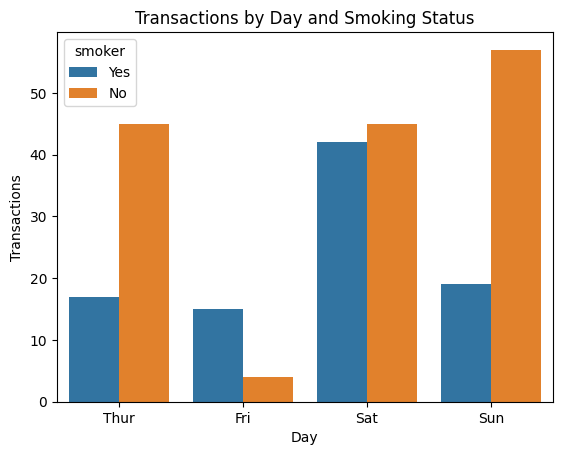

In [25]:
sns.countplot(
    data=tips,
    x="day",
    hue="smoker")

plt.title("Transactions by Day and Smoking Status")
plt.xlabel("Day")
plt.ylabel("Transactions")

plt.show()

> एक ही chart में तीन dimensions effectively दिखाई दे रहे हैं।

In [26]:
# Mean Bar Plot with Hue
# प्रत्येक day पर smoker और non-smoker का average bill क्या है?

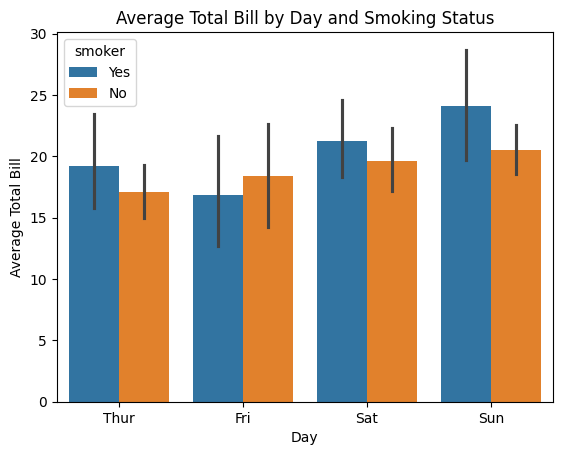

In [27]:
sns.barplot(
    data=tips,
    x="day",
    y="total_bill",
    hue="smoker")

plt.title("Average Total Bill by Day and Smoking Status")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")

plt.show()

#### Chart Selection Framework

जब आपको business question मिले, पहले question की nature पहचानो।


In [30]:
# Heatmap — Introduction
# to show Correlation among many numerical variables

In [29]:
numeric_data = tips.select_dtypes(
    include="number")

corr = numeric_data.corr()
corr

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


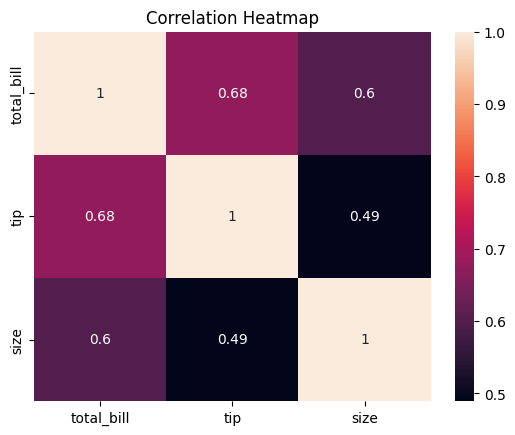

In [31]:
sns.heatmap(corr,annot=True)
plt.title("Correlation Heatmap")
plt.show()

लेकिन ध्यान रहे:
>Correlation does not imply causation. यह Data Analysis interviews में बहुत important statement है।

Visualization का Golden Rule

Chart बनाने से पहले खुद से पूछो:

Question 1
>मैं क्या compare कर रहा हूँ?

Question 2
>क्या मेरा variable categorical है या numerical?

Question 3
>क्या मुझे distribution देखनी है?

Question 4
>क्या मुझे relationship देखनी है?

Question 5
>क्या मुझे trend देखना है?
फिर chart select करो।
Chart पहले नहीं, question पहले।

Professional Visualization Structure
एक अच्छा chart generally:
Title
   ↓
Clear X-axis
   ↓
Clear Y-axis
   ↓
Readable labels
   ↓
Useful legend
   ↓
Minimal clutter

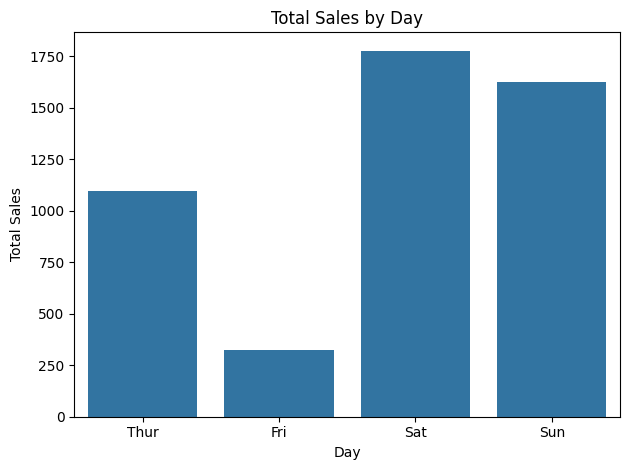

In [32]:
sns.barplot(
    data=day_sales,
    x="day",
    y="total_bill")

plt.title("Total Sales by Day")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
# 36. एक Complete Analysis Example

In [34]:
# Restaurant में किस day पर sales सबसे ज्यादा है और क्या बड़े parties ज्यादा spend करते हैं?"
day_sales = (
    tips.groupby("day", as_index=False)["total_bill"]
        .sum()
        .sort_values("total_bill", ascending=False)
)

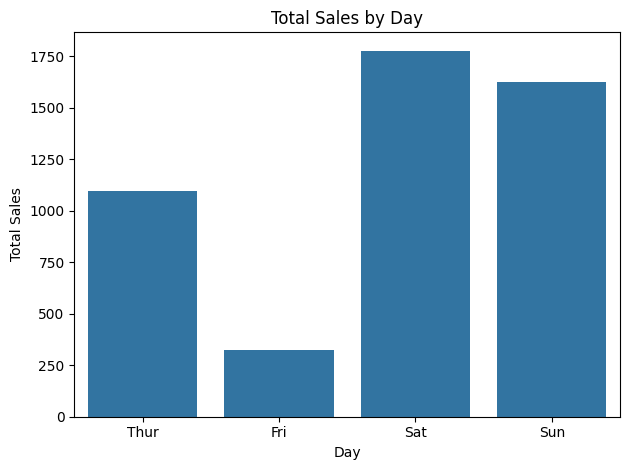

In [35]:
sns.barplot(
    data=day_sales,
    x="day",
    y="total_bill")

plt.title("Total Sales by Day")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

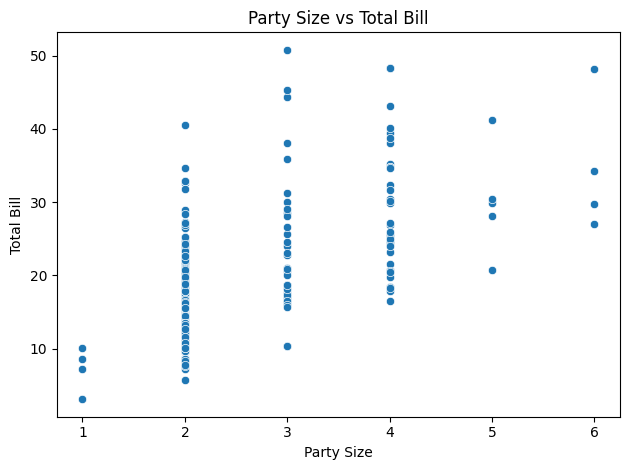

In [36]:
# Relationship
sns.scatterplot(
    data=tips,
    x="size",
    y="total_bill")

plt.title("Party Size vs Total Bill")
plt.xlabel("Party Size")
plt.ylabel("Total Bill")
plt.tight_layout()
plt.show()

39. Interview Questions

Q1. When would you use a histogram?
>जब numerical variable की distribution समझनी हो।

Q2. Bar chart और histogram में difference?
>Bar chart: categorical data comparison.
>Histogram: numerical data distribution.

Q3. Scatter plot कब use करते हैं?
>दो numerical variables के relationship को visualize करने के लिए।

Q4. Box plot का main purpose?
>Distribution, median, spread और potential outliers को समझना।

Q5. Line chart कब use करना चाहिए?
>Ordered/time-series data में trend दिखाने के लिए।

Q6. Correlation क्या बताता है?
>दो numerical variables के बीच linear association की strength और direction।

Q7. क्या high correlation causation prove करता है?

>No.
Correlation ≠ causation.